# IndustReal: data and annotations


## Section 1 - Purpose

This notebook prepares the public dataset IndustReal (Schoonbeek et al. 2024) for the pipeline of this thesis. IndustReal is the first public test of the Phase 1 pipeline: frozen C-RADIOv4 with prototypes from a small support set. If perception holds, the tracking of Phase 2 is tried on it as it stands.

IndustReal contains 84 egocentric recordings of 27 participants, made with a HoloLens 2, who assemble and maintain a toy car built from 3D-printed parts. The data and the code are released under the Apache 2.0 license. Only the RGB images and the annotations are used here.

The recordings are split by participant into train, validation and test, as in the paper. The support set will come from train, the validation frames from validation, and the test frames from test, so that reference frames never come from recordings used for evaluation.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.3: 27 participants; Section 4.4: the split is made on participants, 12 for training, 5 for validation and 10 for testing, to ensure variation in viewpoint, execution and head movements between the three sets.

IndustReal code repository (github.com/TimSchoonbeek/IndustReal), readme: 84 recordings; readme and license.txt: data, code and weights under the Apache 2.0 license.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

In [1]:
# 2.1 Configuration
import json
from pathlib import Path

from remotezip import RemoteZip

# Project folder: the first folder above this notebook that contains src/
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())

# IndustReal on 4TU.ResearchData (doi 10.4121/b008dd74-020d-4ea4-a8ba-7bb60769d224, version 2, Apache-2.0)
DATASET_URL = "https://data.4tu.nl/file/b008dd74-020d-4ea4-a8ba-7bb60769d224/"
ZIP_IDS = {                                    # one zip per part of each split, as listed on the dataset page
    "train_p1": "f58a5f18-9a71-4443-8a48-e59530df9ee8",
    "train_p2": "5aae5141-cece-41db-9681-47acd5300705",
    "train_p3": "4e2ed830-a1fe-40fa-9c5a-2aeae3964616",
    "train_p4": "3ff5409e-165f-4354-9fa4-a4fde639a7a6",
    "val_p1": "bb336949-248c-4ae6-82ef-107dbe61d10f",
    "val_p2": "e899de9f-313a-482b-a6b5-e2de4f38412e",
    "test_p1": "ec7a4f94-7c1d-497d-b75a-4e694b7a9f7e",
    "test_p2": "d07789b6-83b1-429d-be0c-95edba210757",
    "test_p3": "31f88cb6-a2e7-44df-ac51-5aaa0a148fc3",
}
ANNOTATION_PREFIXES = ("AR_labels", "OD_labels", "PSR_labels")   # only the annotations; sensor data (gaze, hands, pose) when needed

# List of the 33 procedure steps and the 11 components, from the IndustReal code repository
PROCEDURE_INFO_URL = "https://raw.githubusercontent.com/TimSchoonbeek/IndustReal/ad86a35d4b5125739e24af677e5d7b55c74af945/PSR/procedure_info.json"   # pinned to the last commit (19 Aug 2024)

DATA_DIR = PROJECT_ROOT / "data" / "industreal"       # not tracked by git (data/* in .gitignore)
RECORDINGS_DIR = DATA_DIR / "recordings"              # one folder per split, one subfolder per recording
PROCEDURE_INFO_PATH = DATA_DIR / "procedure_info.json"
MANIFEST_PATH = DATA_DIR / "annotation_manifest.json"   # list of the annotation files downloaded, per zip
VIDEOS_ZIP_ID = "cf21602e-4424-42a4-b05d-9897957082ad"          # all_rgb_videos.zip on the dataset page
VIDEOS_ZIP_MD5 = "c5b8901dba179d2eb10e9348f8163c79"             # MD5 given on the dataset page
VIDEOS_ZIP_PATH = DATA_DIR / "all_rgb_videos.zip"
VIDEOS_DIR = DATA_DIR / "videos"                                # one mp4 per recording, 10 fps
RGB_COUNTS_PATH = DATA_DIR / "rgb_frame_counts.json"            # number of RGB jpg frames per recording, from the zip indexes
RGB_NUMBERS_PATH = DATA_DIR / "rgb_frame_numbers.json"          # first and last jpg number of every recording, from the zip indexes
FPS = 10                                                        # RGB frame rate (paper, Section 4.2; checked on all videos in 5.5)
SHARPNESS_PATH = DATA_DIR / "train_box_sharpness.csv"           # variance of the Laplacian inside each usable train box, from the videos
SELECTION_SEED = 0                                              # seed of the draw of the evaluation frames, fixed before the draw (as in 8.4)
FRAMES_PER_MOMENT = 11                                          # validation and test: 11 table, 11 pick and 11 mount frames each (Section 9)
EVAL_FRAMES_PATH = PROJECT_ROOT / "configs" / "industreal_eval_frames.csv"   # list of the chosen frames, tracked by git

print("Project folder:", PROJECT_ROOT)
print("Data folder exists:", DATA_DIR.is_dir())

Project folder: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project
Data folder exists: True


------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Annotations

The dataset is published as nine zip files of recordings, three to four per split, of 3.8 to 10.2 GB each. Each recording folder holds every sensor of the headset (RGB, stereo, depth, ambient light), the tracking of gaze, hands and head, and the annotations.

Only the annotation files are needed now. A zip file keeps its index at the end, so the index can be read on the server and single files can be extracted without downloading the whole archive. The sensor data and the RGB frames are downloaded later, and only for the recordings that are used.

The list of the 33 procedure steps and of the 11 components comes from the code repository of the dataset (PSR/procedure_info.json), at its last commit.

In [2]:
# 3.1 Download of the annotations (only the files that are missing)
import urllib.request

def download_annotations():
    """Extract the annotation files of every recording from the remote zips and write the manifest."""
    manifest = {}
    for part, file_id in ZIP_IDS.items():
        split = part.split("_")[0]                                     # train, val or test
        with RemoteZip(DATASET_URL + file_id) as z:                   # reads the zip index on the server
            names = [n for n in z.namelist() if n.split("/")[-1].startswith(ANNOTATION_PREFIXES)]
            for n in names:
                if not (RECORDINGS_DIR / split / n).exists():
                    z.extract(n, RECORDINGS_DIR / split)
        manifest[part] = [f"{split}/{n}" for n in names]
        print(part, len(names), "annotation files")
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=1))

manifest = json.loads(MANIFEST_PATH.read_text()) if MANIFEST_PATH.exists() else None
if manifest is None or not all((RECORDINGS_DIR / f).exists() for files in manifest.values() for f in files):
    download_annotations()
    manifest = json.loads(MANIFEST_PATH.read_text())
else:
    print("All annotation files already present, no download")
print("Annotation files:", sum(len(files) for files in manifest.values()))

if not PROCEDURE_INFO_PATH.exists():
    urllib.request.urlretrieve(PROCEDURE_INFO_URL, PROCEDURE_INFO_PATH)
print("Procedure info present:", PROCEDURE_INFO_PATH.exists())

All annotation files already present, no download
Annotation files: 420
Procedure info present: True


Observation 3.1: The nine zip files hold 420 annotation files, five for each of the 84 recordings: AR_labels.csv, OD_labels.json, PSR_labels.csv, PSR_labels_with_errors.csv and PSR_labels_raw.csv. The recordings are 36 in train, 16 in validation and 32 in test, with 12, 5 and 10 participants, as in the paper.

Inside the zips the recording folders sit at the top level, without the recordings/train, val and test folders shown in the readme, so the split is taken from the name of the zip. Some image folders also contain Thumbs.db, a Windows system file, which is not part of the data.

The names of the recordings have the form participant_procedure_instruction_take, for example 05_assy_0_1 or 14_main_2_3: assy is the assembly and main the maintenance. Every participant has an assy_0 recording and all but participant 15 a main_0 recording. Twenty-two participants have one more recording, four have two (10, 13, 14 and 27), participant 15 has two maintenance recordings with instruction 3, and participant 21 has none (both missing recordings exist as videos only, see Section 5). 

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

IndustReal code repository (github.com/TimSchoonbeek/IndustReal), readme, Data information and Annotation information: the content of each recording folder and the meaning of the five annotation files; PSR/procedure_info.json, at commit ad86a35 (19 August 2024): the 33 procedure steps and the 11 components.

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.3: each participant performed a correct assembly instruction, a correct maintenance instruction and one or two instructions with errors.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Components and procedure steps

IndustReal does not annotate single parts. It divides the toy car into 11 components, each made of one or more parts, and describes the state of the assembly as the state of each component: installed correctly, not installed yet, or installed incorrectly. The procedure steps are defined on the same components: each component can be installed, installed incorrectly or removed, which gives the 33 steps of the procedure.

The components are what Phase 2 and Phase 3 will reason about, so their list and their order are read first. Whether the perception of Phase 1 can work on whole components or needs the single parts is decided later, on the frames.

In [3]:
# 4.1 The 11 components and their procedure steps
procedure = json.loads(PROCEDURE_INFO_PATH.read_text())
print(len(procedure), "procedure steps")

COMPONENTS = []                                                   # component names, in the order of the state vector
for idx in sorted({s["state_idx"] for s in procedure}):
    steps = [s for s in procedure if s["state_idx"] == idx]
    install = next(s for s in steps if s["install"] and not s["description"].startswith("Incorrectly"))
    COMPONENTS.append(install["description"].removeprefix("Install "))
    print(idx, COMPONENTS[-1], "| step ids", [s["id"] for s in steps],
          "| expected in assembly:", install["expected_in_assy"], "| in maintenance:", install["expected_in_main"])

33 procedure steps
0 base | step ids [0, 1, 2] | expected in assembly: False | in maintenance: False
1 front chassis | step ids [3, 4, 5] | expected in assembly: True | in maintenance: False
2 front chassis pin | step ids [6, 7, 8] | expected in assembly: True | in maintenance: False
3 rear chassis | step ids [9, 10, 11] | expected in assembly: True | in maintenance: False
4 short rear chassis | step ids [12, 13, 14] | expected in assembly: False | in maintenance: True
5 front rear chassis pin | step ids [15, 16, 17] | expected in assembly: True | in maintenance: True
6 rear rear chassis pin | step ids [18, 19, 20] | expected in assembly: True | in maintenance: True
7 front bracket | step ids [21, 22, 23] | expected in assembly: True | in maintenance: False
8 front bracket screw | step ids [24, 25, 26] | expected in assembly: True | in maintenance: False
9 front wheel assy | step ids [27, 28, 29] | expected in assembly: True | in maintenance: False
10 rear wheel assy | step ids [30, 31

Observation 4.1: The procedure has 33 steps on 11 components, three per component with consecutive ids: installed (3 × index), installed incorrectly (3 × index + 1) and removed (3 × index + 2). The base is expected in neither procedure, since it is on the desk from the start. The short rear chassis is expected only in maintenance, the front chassis, its pin, the front bracket, its screw and the front wheel only in assembly, and the two pins of the rear chassis and the rear wheel in both. This agrees with the paper, where maintenance replaces the long braces of the rear chassis with short ones.

In [4]:
# 4.2 Erroneous steps per recording, by instruction
import csv

def read_rows(path):
    """Rows of a csv annotation file, as tuples, without empty lines."""
    return [tuple(r) for r in csv.reader(open(path)) if r]

recordings = sorted(p for split in ("train", "val", "test") for p in (RECORDINGS_DIR / split).iterdir() if p.is_dir())
summary = []
for rec in recordings:
    participant, task, instruction, take = rec.name.split("_")
    correct = read_rows(rec / "PSR_labels.csv")
    with_errors = read_rows(rec / "PSR_labels_with_errors.csv")
    errors = [r for r in with_errors if r not in correct]           # steps that appear only in the file with errors
    summary.append((rec.parent.name, rec.name, task, instruction, len(correct), len(errors)))

for label, rows in [("instruction 0", [s for s in summary if s[3] == "0"]), ("other instructions", [s for s in summary if s[3] != "0"])]:
    print(label, ":", len(rows), "recordings,", sum(s[5] > 0 for s in rows), "with erroneous steps")
print()
for s in summary:
    if s[5] > 0 or s[3] != "0":
        print(s)

instruction 0 : 53 recordings, 5 with erroneous steps
other instructions : 31 recordings, 25 with erroneous steps

('test', '03_assy_1_3', 'assy', '1', 10, 2)
('test', '08_assy_0_1', 'assy', '0', 10, 2)
('test', '08_assy_2_4', 'assy', '2', 8, 1)
('test', '08_main_0_1', 'main', '0', 10, 1)
('test', '09_assy_3_1', 'assy', '3', 8, 1)
('test', '10_assy_3_2', 'assy', '3', 15, 1)
('test', '10_main_3_4', 'main', '3', 8, 0)
('test', '12_assy_3_4', 'assy', '3', 8, 1)
('test', '12_main_0_1', 'main', '0', 12, 1)
('test', '13_main_1_3', 'main', '1', 7, 1)
('test', '13_main_2_1', 'main', '2', 8, 0)
('test', '17_assy_0_1', 'assy', '0', 9, 2)
('test', '17_assy_1_5', 'assy', '1', 8, 1)
('test', '18_assy_2_5', 'assy', '2', 7, 3)
('test', '19_assy_3_5', 'assy', '3', 8, 1)
('test', '23_assy_1_2', 'assy', '1', 8, 1)
('train', '01_assy_1_1', 'assy', '1', 8, 1)
('train', '02_assy_0_1', 'assy', '0', 11, 1)
('train', '02_assy_1_2', 'assy', '1', 8, 1)
('train', '04_assy_2_1', 'assy', '2', 8, 2)
('train', '06_a

Observation 4.2: Of the 53 recordings with instruction 0, only 5 have steps executed incorrectly: 02_assy_0_1, 08_assy_0_1, 08_main_0_1, 12_main_0_1 and 17_assy_0_1. Of the 31 recordings with other instructions, 25 have them. Instruction 0 is therefore the correct instruction, and the five exceptions are mistakes made while following it, as the paper reports.

The six recordings with another instruction and no incorrect step are 10_main_3_4, 13_main_2_1, 14_main_2_2, 14_main_2_3, 22_assy_2_3 and 25_assy_2_1. A missing step does not appear among the incorrect ones, so their errors may be omissions (checked in 4.4 and 4.5).

The state of the components is annotated in PSR_labels_raw.csv, one row each time it changes. Two things are checked on it: how a removal appears, on the one recording where a component goes back from installed to not installed, and whether the recordings with an erroneous instruction but no incorrect step end in a different state from the correct ones.

In [5]:
# 4.3 Steps and state changes of one recording (05_assy_0_1)
def read_states(rec):
    """Frame and state vector (11 integers: 1 correct, 0 not installed, -1 incorrect) of every row of PSR_labels_raw.csv."""
    return [(r[0], [int(v) for v in r[1:]]) for r in read_rows(rec / "PSR_labels_raw.csv")]

def state_changes(previous, current):
    """Components whose value changes between two state vectors."""
    return [f"{COMPONENTS[i]} {a} -> {b}" for i, (a, b) in enumerate(zip(previous, current)) if a != b]

rec = RECORDINGS_DIR / "val" / "05_assy_0_1"
print("PSR_labels_with_errors.csv:")
for r in read_rows(rec / "PSR_labels_with_errors.csv"):
    print("  ", r)

states = read_states(rec)
print("PSR_labels_raw.csv, state changes:")
print("  ", states[0][0], "start", states[0][1])
for (_, previous), (frame, current) in zip(states, states[1:]):
    print("  ", frame, state_changes(previous, current))

PSR_labels_with_errors.csv:
   ('000521.jpg', '3', 'Install front chassis')
   ('000521.jpg', '6', 'Install front chassis pin')
   ('000783.jpg', '9', 'Install rear chassis')
   ('000783.jpg', '15', 'Install front rear chassis pin')
   ('000899.jpg', '18', 'Install rear rear chassis pin')
   ('001416.jpg', '30', 'Install rear wheel assy')
   ('002233.jpg', '17', 'Remove front rear chassis pin')
   ('002349.jpg', '15', 'Install front rear chassis pin')
   ('002456.jpg', '21', 'Install front bracket')
   ('002456.jpg', '24', 'Install front bracket screw')
   ('002870.jpg', '27', 'Install front wheel assy')
PSR_labels_raw.csv, state changes:
   000000.jpg start [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
   000521.jpg ['front chassis 0 -> 1', 'front chassis pin 0 -> 1']
   000783.jpg ['rear chassis 0 -> 1', 'front rear chassis pin 0 -> 1']
   000899.jpg ['rear rear chassis pin 0 -> 1']
   001416.jpg ['rear wheel assy 0 -> 1']
   002233.jpg ['front rear chassis pin 1 -> 0']
   002349.jpg ['front rea

Observation 4.3: In 05_assy_0_1 the front rear chassis pin is removed at frame 2233 and installed again at frame 2349, about 12 s later at 10 fps. Both steps are annotated in PSR_labels.csv as well (step 17, remove, and step 15, install), so a removal followed by a new installation is a correction during the execution, not an incorrect step. The order is flexible: the front bracket is installed after the rear wheel.

In [6]:
# 4.4 Final states: correct recordings against recordings with an erroneous instruction and no incorrect step
from collections import Counter

by_name = {r.name: r for r in recordings}
clean = [s for s in summary if s[3] == "0" and s[5] == 0]         # instruction 0 and no incorrect step

for task in ("assy", "main"):
    finals = Counter(tuple(read_states(by_name[s[1]])[-1][1]) for s in clean if s[2] == task)
    print(task, ":", sum(finals.values()), "correct recordings; most common final states:")
    for state, n in finals.most_common(3):
        print("  ", list(state), n)

print()
for name in ["10_main_3_4", "13_main_2_1", "14_main_2_2", "14_main_2_3", "22_assy_2_3", "25_assy_2_1"]:
    print(name, read_states(by_name[name])[-1][1])

assy : 24 correct recordings; most common final states:
   [1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1] 24
main : 24 correct recordings; most common final states:
   [1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1] 24

10_main_3_4 [1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1]
13_main_2_1 [1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1]
14_main_2_2 [1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1]
14_main_2_3 [1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1]
22_assy_2_3 [1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1]
25_assy_2_1 [1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1]


Observation 4.4: The 48 recordings with the correct instruction and no incorrect step all end in the same state, 24 for each task. An assembly ends with every component installed except the short rear chassis. A maintenance ends with the rear chassis removed and the short rear chassis installed in its place.

Of the six recordings with an erroneous instruction and no incorrect step, two end without a pin (14_main_2_2, 25_assy_2_1), two maintenances end with the rear chassis still installed and no short rear chassis (13_main_2_1, and 14_main_2_3, which also lacks a pin), one assembly ends with the short rear chassis in place of the rear chassis (22_assy_2_3), and one ends in the correct final state (10_main_3_4).

The errors of IndustReal are therefore of several kinds: components installed incorrectly, components left out, and the component of the other procedure installed in place of the right one. 10_main_3_4 had an erroneous instruction but its annotations show no error (see 4.5). Why the two maintenances keep the rear chassis, whether the replacement was skipped, is not checked here: it would need their initial state (hypothesis).

The paper reports 35 videos with a missing or incorrect step and 38 incorrect step completions. They are checked here on the annotations. A recording has errors, as in the function video_contains_errors of the dataset code, if a step expected for its task is never completed, or if a component is ever installed incorrectly (a -1 in PSR_labels_raw.csv).

In [7]:
# 4.5 Recordings with errors, by the definition of the dataset authors
expected_steps = {task: {s["id"] for s in procedure if s[f"expected_in_{task}"]} for task in ("assy", "main")}

def find_errors(rec):
    """As video_contains_errors in PSR/psr_utils.py: expected steps never completed, and whether a component is ever incorrect."""
    task = rec.name.split("_")[1]
    completed = {int(r[1]) for r in read_rows(rec / "PSR_labels.csv")}
    missing = sorted(expected_steps[task] - completed)
    incorrect = any(-1 in state for _, state in read_states(rec))
    return missing, incorrect

recordings_with_errors = []
for rec in recordings:
    missing, incorrect = find_errors(rec)
    if missing or incorrect:
        recordings_with_errors.append((rec.name, missing, incorrect))

print(len(recordings_with_errors), "of", len(recordings), "recordings with errors (paper: 35)")
print(sum(s[5] for s in summary), "incorrect step completions (paper: 38)")
print()
for name, missing, incorrect in recordings_with_errors:
    print(name, "| missing steps:", missing, "| incorrect component:", incorrect)

35 of 84 recordings with errors (paper: 35)
38 incorrect step completions (paper: 38)

03_assy_1_3 | missing steps: [30] | incorrect component: True
08_assy_0_1 | missing steps: [24] | incorrect component: True
08_assy_2_4 | missing steps: [24] | incorrect component: True
08_main_0_1 | missing steps: [] | incorrect component: True
09_assy_3_1 | missing steps: [15] | incorrect component: True
10_assy_3_2 | missing steps: [18] | incorrect component: True
12_assy_3_4 | missing steps: [27] | incorrect component: True
12_main_0_1 | missing steps: [] | incorrect component: True
13_main_1_3 | missing steps: [30] | incorrect component: True
13_main_2_1 | missing steps: [12] | incorrect component: False
17_assy_0_1 | missing steps: [] | incorrect component: True
17_assy_1_5 | missing steps: [30] | incorrect component: True
18_assy_2_5 | missing steps: [21, 24] | incorrect component: True
19_assy_3_5 | missing steps: [30] | incorrect component: True
23_assy_1_2 | missing steps: [27] | incorrect 

Observation 4.5: With the definition of the dataset code, 35 of the 84 recordings have errors and the incorrect step completions are 38 in total, the two numbers of the paper. In 30 of them a component is installed incorrectly, and its correct installation then never follows in most of them. The other five have only missing steps: 13_main_2_1, 14_main_2_2, 14_main_2_3, 22_assy_2_3 and 25_assy_2_1. 10_main_3_4 has an erroneous instruction but no error in its annotations, so it counts as a recording without errors.

The steps most often missing are the installation of the rear wheel (30), of the front wheel (27), of the two pins of the rear chassis (15, 18) and of the front bracket screw (24).

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

IndustReal code repository, PSR/procedure_info.json at commit ad86a35: the 33 steps and the fields install, state_idx, expected_in_assy and expected_in_main.

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.4.2: the 11 components, in the order of the state vector, and the values 1, 0 and -1; Figure 1: parts, components and the maintenance task.

Schoonbeek et al. 2024, IndustReal (WACV), Section 1: procedural errors (e.g. omissions) and execution errors (e.g. wrong type of nut used); Section 4.3: participants also made mistakes with the correct instructions, and these were annotated.

Schoonbeek et al. 2024, IndustReal (WACV), Section 3.1: the procedural information P, a set of actions each described by information such as a description, an image of the completed step or relative positions between components; Section 4.4.3: 724 correct and 38 incorrect step completions, 35 videos with a missing or incorrect step.

IndustReal code repository, PSR/psr_utils.py at commit ad86a35: convert_states_to_steps (how changes of state become steps, including removals) and video_contains_errors (a video has errors if an expected step is missing or a component is ever installed incorrectly).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - RGB videos

In [8]:
# 5.1 Content of the video archive
import zipfile

VIDEOS_ZIP_PATH = DATA_DIR / "all_rgb_videos.zip"

with zipfile.ZipFile(VIDEOS_ZIP_PATH) as z:
    entries = z.infolist()
mp4 = [e for e in entries if e.filename.endswith(".mp4")]
print(len(entries), "entries,", len(mp4), "mp4 files,", round(sum(e.file_size for e in mp4) / 1e9, 2), "GB")
print("Other entries:", [e.filename for e in entries if not e.filename.endswith(".mp4")])
print("Folders of the mp4 files:", sorted({str(Path(e.filename).parent) for e in mp4}))

86 entries, 86 mp4 files, 5.05 GB
Other entries: []
Folders of the mp4 files: ['.']


In [9]:
# 5.2 Videos against recordings
video_names = {Path(e.filename).stem for e in mp4}
recording_names = {r.name for r in recordings}
print("Videos without annotations:", sorted(video_names - recording_names))
print("Recordings without a video:", sorted(recording_names - video_names))

Videos without annotations: ['15_main_0_1', '21_assy_1_1']
Recordings without a video: []


Observation 5.2: The archive holds 86 videos, one for each of the 84 annotated recordings and two more: 15_main_0_1 and 21_assy_1_1. These are the two recordings missing from the nine zip files, so participant 15 did record a correct maintenance and participant 21 an instruction with errors, as the paper describes, but neither has frames or annotations. Neither the readme nor the paper says why. They are left out of every selection, since nothing can be measured on them.

In [10]:
# 5.3 Download, integrity check and extraction of the videos (only what is missing)
import hashlib
import shutil
import urllib.request

def md5_of(path, block_size=2**24):
    """MD5 of a file, read in blocks of 16 MB."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(block_size):
            h.update(block)
    return h.hexdigest()

if VIDEOS_DIR.is_dir() and len(list(VIDEOS_DIR.glob("*.mp4"))) == len(mp4):
    print("All videos already extracted, no download")
else:
    if not VIDEOS_ZIP_PATH.exists():
        print("Downloading the video archive (about 5 GB)")
        with urllib.request.urlopen(DATASET_URL + VIDEOS_ZIP_ID) as r, open(VIDEOS_ZIP_PATH, "wb") as f:
            shutil.copyfileobj(r, f, 2**24)
    digest = md5_of(VIDEOS_ZIP_PATH)
    assert digest == VIDEOS_ZIP_MD5, f"MD5 mismatch: {digest}"
    print("MD5 matches the dataset page")
    with zipfile.ZipFile(VIDEOS_ZIP_PATH) as z:
        z.extractall(VIDEOS_DIR)
print("Videos in", VIDEOS_DIR, ":", len(list(VIDEOS_DIR.glob("*.mp4"))))

All videos already extracted, no download
Videos in c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\industreal\videos : 86


Observation 5.3: The 86 videos are extracted into data/industreal/videos, after the MD5 of the archive matched the one on the dataset page. A second run does nothing.

The readme gives 1080x720 for the RGB frames, the paper 1280x720 (Section 4.2). The size of one frame of the dataset is read here, together with the size, frame rate and length of the video of the same recording.

In [11]:
# 5.4 Resolution and frame rate: one RGB frame of the dataset against its video
import io
import cv2
from PIL import Image

rec_name = "05_assy_0_1"
with RemoteZip(DATASET_URL + ZIP_IDS["val_p1"]) as z:            # reads only the index and one frame
    rgb_names = sorted(n for n in z.namelist() if n.startswith(rec_name + "/rgb/") and n.endswith(".jpg"))
    frame = Image.open(io.BytesIO(z.read(rgb_names[0])))
print(rec_name, ":", len(rgb_names), "RGB frames, first frame", frame.size, "(width, height)")

video = cv2.VideoCapture(str(VIDEOS_DIR / f"{rec_name}.mp4"))
print("Video:", int(video.get(cv2.CAP_PROP_FRAME_WIDTH)), "x", int(video.get(cv2.CAP_PROP_FRAME_HEIGHT)),
      "|", video.get(cv2.CAP_PROP_FPS), "fps |", int(video.get(cv2.CAP_PROP_FRAME_COUNT)), "frames")
video.release()

05_assy_0_1 : 2918 RGB frames, first frame (1280, 720) (width, height)
Video: 1280 x 720 | 10.0 fps | 2918 frames


Observation 5.4: The RGB frames of 05_assy_0_1 are 1280x720, as in the paper; the 1080x720 of the readme is an error. Its video has the same size, runs at 10 fps and has 2918 frames, as many as the jpg frames, so the frame n of the video corresponds to the jpg frame n. The video is compressed, so its pixels are not identical to those of the jpg: the videos serve for looking at the recordings, the jpg frames for annotation and measurement.

In [12]:
# 5.5 All videos against the RGB frames of their recordings
if RGB_COUNTS_PATH.exists():
    rgb_counts = json.loads(RGB_COUNTS_PATH.read_text())
else:
    rgb_counts = {}
    for part, file_id in ZIP_IDS.items():
        with RemoteZip(DATASET_URL + file_id) as z:               # reads only the index of each zip
            for n in z.namelist():
                parts = n.split("/")
                if len(parts) == 3 and parts[1] == "rgb" and n.endswith(".jpg"):
                    rgb_counts[parts[0]] = rgb_counts.get(parts[0], 0) + 1
    RGB_COUNTS_PATH.write_text(json.dumps(rgb_counts, indent=1))

differences = []
for rec_name, n_frames in sorted(rgb_counts.items()):
    video = cv2.VideoCapture(str(VIDEOS_DIR / f"{rec_name}.mp4"))
    info = (int(video.get(cv2.CAP_PROP_FRAME_WIDTH)), int(video.get(cv2.CAP_PROP_FRAME_HEIGHT)),
            video.get(cv2.CAP_PROP_FPS), int(video.get(cv2.CAP_PROP_FRAME_COUNT)))
    video.release()
    if info != (1280, 720, 10.0, n_frames):
        differences.append((rec_name, info, n_frames))

print(len(rgb_counts), "recordings,", sum(rgb_counts.values()), "RGB frames in total")
print("Videos that differ from their frames (size, fps or length):", differences)

84 recordings, 207072 RGB frames in total
Videos that differ from their frames (size, fps or length): [('11_assy_0_1', (1280, 720, 10.0, 2572), 2571)]


In [13]:
# 5.6 Frames of 11_assy_0_1 counted by decoding the video
video = cv2.VideoCapture(str(VIDEOS_DIR / "11_assy_0_1.mp4"))
decoded = 0
while video.grab():                                                # grab() decodes the next frame without converting it
    decoded += 1
video.release()
print("Decoded frames:", decoded, "| jpg frames:", rgb_counts["11_assy_0_1"])

Decoded frames: 2572 | jpg frames: 2571


Observation 5.5-5.6: The 84 recordings hold 207,072 RGB frames, so the 26.9K frames annotated for ASD are 13% of them, as in the paper (Section 4.4.2). 83 videos are 1280x720 at 10 fps with as many frames as their jpg frames. The video of 11_assy_0_1 has one frame more, 2572 against 2571, also when its frames are counted by decoding, so its frame count is not an error of the file header. The extra frame is video frame 0, and the jpg numbering of this recording is shifted (see 5.7-5.8).

The videos are therefore used for looking and for measures computed on the frames (sharpness, Section 8), always converting the jpg number into the video index with the offset found in 5.8. A frame chosen on a video is confirmed on its jpg frame before it is annotated, so that an offset cannot enter the annotations.

In [14]:
# 5.7 Numbering of the jpg frames of every recording
if RGB_NUMBERS_PATH.exists():
    rgb_numbers = json.loads(RGB_NUMBERS_PATH.read_text())
else:
    numbers = {}
    for part, file_id in ZIP_IDS.items():
        with RemoteZip(DATASET_URL + file_id) as z:
            for n in z.namelist():
                parts = n.split("/")
                if len(parts) == 3 and parts[1] == "rgb" and n.endswith(".jpg"):
                    numbers.setdefault(parts[0], []).append(int(parts[2][:-4]))
    rgb_numbers = {r: [min(v), max(v), len(v)] for r, v in numbers.items()}
    RGB_NUMBERS_PATH.write_text(json.dumps(rgb_numbers, indent=1))

not_from_zero = {r: v for r, v in rgb_numbers.items() if v[0] != 0}
with_gaps = {r: v for r, v in rgb_numbers.items() if v[1] - v[0] + 1 != v[2]}
print(len(rgb_numbers), "recordings")
print("Numbering not starting at 0 (first, last, count):", not_from_zero)
print("Numbering with gaps:", with_gaps)

84 recordings
Numbering not starting at 0 (first, last, count): {'11_assy_0_1': [30, 2600, 2571]}
Numbering with gaps: {}


In [15]:
# 5.8 Offset between the video and the jpg frames of 11_assy_0_1: video index = jpg number - offset
import cv2
import numpy as np
import pandas as pd

REC = "11_assy_0_1"
JPG_NUMBERS = [30, 500, 1300, 2100, 2600]
OFFSETS = range(0, 41)

def small_gray(image):
    return cv2.resize(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (320, 180)).astype(np.float32)

jpgs = {}
for file_id in ZIP_IDS.values():
    with RemoteZip(DATASET_URL + file_id) as z:
        if f"{REC}/rgb/{JPG_NUMBERS[0]:06d}.jpg" in z.namelist():
            for k in JPG_NUMBERS:
                data = np.frombuffer(z.read(f"{REC}/rgb/{k:06d}.jpg"), np.uint8)
                jpgs[k] = small_gray(cv2.imdecode(data, cv2.IMREAD_COLOR))
            break

wanted = {k - o for k in JPG_NUMBERS for o in OFFSETS}
video = cv2.VideoCapture(str(VIDEOS_DIR / f"{REC}.mp4"))
frames, i = {}, 0
while True:
    ok, image = video.read()
    if not ok:
        break
    if i in wanted:
        frames[i] = small_gray(image)
    i += 1
video.release()

diff = pd.DataFrame({o: [np.abs(jpgs[k] - frames[k - o]).mean() if k - o in frames else np.nan
                         for k in JPG_NUMBERS] for o in OFFSETS}, index=JPG_NUMBERS).T
diff.index.name = "offset"
print(diff.round(1).to_string())
print("Best offset for every jpg:", diff.idxmin().to_dict())
VIDEO_OFFSET = {REC: int(diff[30].idxmin())}          # video index = jpg number - offset; 0 for every other recording
print("Video offsets:", VIDEO_OFFSET)

        30    500   1300  2100  2600
offset                              
0       21.3  57.6  31.0  42.0   NaN
1       18.4  57.1  30.2  42.1   NaN
2       21.1  56.8  42.9  42.1   NaN
3       23.1  56.7  34.6  42.1   NaN
4       23.8  57.3  35.1  42.1   NaN
5       22.3  59.0  34.2  42.0   NaN
6       22.3  60.8  31.8  41.7   NaN
7       21.2  56.2  30.7  41.8   NaN
8       21.1  53.2  29.8  42.0   NaN
9       20.4  50.9  29.9  40.8   NaN
10      20.6  51.7  35.9  40.5   NaN
11      21.5  50.1  35.6  41.1   NaN
12      21.1  46.0  34.8  40.9   NaN
13      21.6  38.5  34.2  40.4   NaN
14      22.5  35.1  37.5  39.9   NaN
15      22.4  34.3  37.8  40.5   NaN
16      22.6  33.9  39.8  40.5   NaN
17      22.5  33.7  43.4  39.5   NaN
18      23.0  33.5  46.0  39.0   NaN
19      22.2  32.5  46.4  38.3   NaN
20      21.1  29.8  45.7  36.3   NaN
21      20.4  26.8  46.1  34.0   NaN
22      19.7  26.4  45.0  32.1   NaN
23      19.2  25.9  42.3  28.5   NaN
24      18.6  23.8  32.0  25.2   NaN
2

Observation 5.7-5.8: In 83 of the 84 recordings the jpg frames are numbered from 0 with no gaps, and there are as many as the video frames. In 11_assy_0_1 they are numbered from 30 to 2600 (2571 files, no gaps), and the OD boxes use the same numbering. Comparing five jpg frames, taken from the start to the end of the recording, with the video frames gives the same offset, 29, at all five points (mean absolute difference about 4, against at least 8 at the other offsets). So jpg n is video frame n - 29: video frame 0 has no jpg, and no frame is duplicated or missing in between. Whenever a jpg number is used to read the video, this offset must be subtracted.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.2: RGB camera at 1280x720, 10 fps; Section 4.4.2: 26.9K frames (13% of the total) annotated for ASD.

IndustReal code repository, readme (Data information): RGB at 1080x720 and 10 fps, the size contradicted by the frames. IndustReal on 4TU.ResearchData (doi 10.4121/b008dd74-020d-4ea4-a8ba-7bb60769d224): all_rgb_videos.zip and its MD5.

IndustReal issue #7 (github.com/TimSchoonbeek/IndustReal/issues/7): the dataset page was unreachable for some days in November 2026, a reason to keep a local copy of what is used.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Action annotations

AR_labels.csv lists the actions of each recording: an action id, its name, made of a verb and a noun, and the first and last frame. The paper reports 75 action classes, 9,273 instances, an average duration of 1.9 ± 1.4 s, 110 ± 38 actions per recording (134 ± 32 in assembly, 79 ± 13 in maintenance) and 24.2% of the instances overlapping another one (Section 4.4.1); the supplementary material gives 73 classes in its text and 75 in its Figure 4. These numbers are checked on the annotations.

In [16]:
# 6.1 Action annotations: classes, instances, durations and overlaps
import statistics

actions = []                                                       # (recording, task, action id, name, first frame, last frame)
for rec in recordings:
    for r in read_rows(rec / "AR_labels.csv"):
        actions.append((rec.name, rec.name.split("_")[1], int(r[1]), r[2], int(r[3][:-4]), int(r[4][:-4])))

names_by_id = {}
for a in actions:
    names_by_id.setdefault(a[2], set()).add(a[3])
print(len(actions), "action instances (paper: 9,273)")
print(len(names_by_id), "action ids, from", min(names_by_id), "to", max(names_by_id), "(paper: 75 classes)")
print("Ids with more than one name:", {i: n for i, n in names_by_id.items() if len(n) > 1})
print("Verbs:", sorted({n.split("_")[0] for names in names_by_id.values() for n in names}))

durations = [(a[5] - a[4]) / FPS for a in actions]
print(f"Duration: {statistics.mean(durations):.1f} ± {statistics.stdev(durations):.1f} s (paper: 1.9 ± 1.4 s)")

for label, task in [("all", None), ("assembly", "assy"), ("maintenance", "main")]:
    counts = [sum(a[0] == rec.name for a in actions) for rec in recordings if task in (None, rec.name.split("_")[1])]
    print(f"Actions per recording, {label}: {statistics.mean(counts):.0f} ± {statistics.stdev(counts):.0f}")

overlapping = 0
for rec in recordings:
    own = [a for a in actions if a[0] == rec.name]
    overlapping += sum(any(b is not a and a[4] < b[5] and b[4] < a[5] for b in own) for a in own)
print(f"Instances overlapping another one: {100 * overlapping / len(actions):.1f}% (paper: 24.2%)")

9273 action instances (paper: 9,273)
74 action ids, from 0 to 74 (paper: 75 classes)
Ids with more than one name: {}
Verbs: ['align', 'browse', 'check', 'fit', 'loosen', 'plug', 'pull', 'put', 'take', 'tighten']
Duration: 1.9 ± 1.5 s (paper: 1.9 ± 1.4 s)
Actions per recording, all: 110 ± 38
Actions per recording, assembly: 134 ± 33
Actions per recording, maintenance: 78 ± 14
Instances overlapping another one: 42.7% (paper: 24.2%)


In [17]:
# 6.2 Missing action id, class list, and the overlap measured in other ways
from collections import Counter

all_ids = set(range(min(names_by_id), max(names_by_id) + 1))
print("Ids never used:", sorted(all_ids - set(names_by_id)))
counts = Counter(a[2] for a in actions)
for i in sorted(names_by_id):
    print(i, next(iter(names_by_id[i])), counts[i])

pairs, long_overlap, nested = 0, set(), set()
for rec in recordings:
    own = [a for a in actions if a[0] == rec.name]
    for i, a in enumerate(own):
        for b in own[i + 1:]:
            shared = min(a[5], b[5]) - max(a[4], b[4])              # frames shared by the two intervals
            if shared > 0:
                pairs += 1
                if shared >= FPS:
                    long_overlap |= {id(a), id(b)}
                if (a[4] <= b[4] and b[5] <= a[5]) or (b[4] <= a[4] and a[5] <= b[5]):
                    nested |= {id(a), id(b)}
print()
print(f"Overlapping pairs over all instances: {100 * pairs / len(actions):.1f}%")
print(f"Instances overlapping another one by at least 1 s: {100 * len(long_overlap) / len(actions):.1f}%")
print(f"Instances in a nested pair (one inside the other): {100 * len(nested) / len(actions):.1f}%")

Ids never used: [37]
0 take_short_brace 134
1 align_objects 569
2 take_pin_short 245
3 plug_short_pin 251
4 take_tooth_washer 395
5 take_nut 437
6 tighten_nut 464
7 check_instruction 1300
8 take_partial_model 302
9 take_long_brace 119
10 take_screw_pin 73
11 take_instruction 3
12 put_instruction 4
13 take_pin_long 59
14 put_pin_long 15
15 take_wing_beam 61
16 plug_screw_pin 61
17 take_round_washer 358
18 take_acorn_nut 58
19 tighten_acorn_nut 61
20 take_pin_middle 76
21 take_wheel 298
22 plug_pin_long 46
23 take_wing 74
24 put_wing 17
25 plug_partial_model 4
26 plug_pin_middle 81
27 take_pulley 107
28 plug_wheel 8
29 browse_instruction 134
30 fit_short_brace 110
31 fit_tooth_washer 386
32 fit_round_washer 292
33 fit_long_brace 18
34 fit_nut 414
35 put_screw_pin 20
36 put_wheel 76
38 pull_wheel 9
39 loosen_nut 128
40 put_nut 90
41 pull_objects 53
42 put_pin_middle 28
43 take_objects 321
44 put_partial_model 296
45 put_objects 201
46 pull_pin_short 90
47 put_pin_short 77
48 put_long_brac

Observation 6.1-6.2: The annotations hold 9,273 action instances, as in the paper. Their duration is 1.9 ± 1.5 s and their number per recording 110 ± 38, 134 ± 33 in assembly and 78 ± 14 in maintenance, equal to the paper up to rounding. Every id has a single name.

The ids go from 0 to 74, but id 37 is never used: 75 classes are defined and 74 occur. The 75 of the paper matches the defined classes; the 73 of the text of the supplementary material is not found in the data. Only 10 of the 12 verbs of MECCANO occur: screw and unscrew are never used, and the screw pin is installed with plug. The most frequent classes are check_instruction (1,300) and align_objects (569), and 23 classes cover 80% of the instances, as in the supplementary material; three classes occur only once.

The share of instances overlapping another one is 42.7% when any shared frame counts, against 24.2% in the paper. Neither the overlapping pairs over all instances (26.7%), nor an overlap of at least 1 s (14.8%), nor nested pairs (10.3%) gives the number of the paper, whose definition is not stated. The difference is left unexplained, since the actions are not an input of the pipeline of this thesis.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.4.1: verbs adopted from MECCANO, 75 action classes, 9,273 instances, duration 1.9 ± 1.4 s, 110 ± 38 actions per recording (134 ± 32 assembly, 79 ± 13 maintenance), 24.2% overlapping instances.

Schoonbeek et al. 2024, supplementary material (arXiv 2310.17323), Section 7.2.1: start frames at the initiation of the action, annotation with ELAN by two annotators who reviewed each other; 73 classes in the text and 75 in Figure 4; check_instruction and align_objects the most frequent classes, 23 classes covering 80% of the data.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - The assembly in frames

The assembly of one recording is looked at frame by frame instead of as a video: the frame of each completed step (PSR) and a few frames before it, with the bounding box of the assembly state where one is annotated. The recording is 05_assy_0_1, from the validation set, so that looking at it does not influence the choice of the support set. First, the format of the bounding boxes in OD_labels.json is read.

In [18]:
# 7.1 Format of OD_labels.json (one recording)
rec = RECORDINGS_DIR / "val" / "05_assy_0_1"
od = json.loads((rec / "OD_labels.json").read_text())

print(len(od["images"]), "images,", len(od["annotations"]), "boxes,", len(od["categories"]), "categories")
print("First image:", od["images"][0])
print("First box:", od["annotations"][0])
print("Categories:")
for c in od["categories"]:
    print("  ", c)

155 images, 155 boxes, 24 categories
First image: {'id': 0, 'file_name': '000000.jpg', 'width': 1280, 'height': 720}
First box: {'id': 1, 'image_id': 0, 'category_id': 1, 'bbox': [519.0, 348.0, 213.0, 368.0], 'area': 78384.0, 'iscrowd': 0}
Categories:
   {'id': 1, 'name': 'background'}
   {'id': 2, 'name': '10000000000'}
   {'id': 3, 'name': '10010010000'}
   {'id': 4, 'name': '10010100000'}
   {'id': 5, 'name': '10010110000'}
   {'id': 6, 'name': '11100000000'}
   {'id': 7, 'name': '11110010000'}
   {'id': 8, 'name': '11110100000'}
   {'id': 9, 'name': '11110110000'}
   {'id': 10, 'name': '11110111100'}
   {'id': 11, 'name': '11110111110'}
   {'id': 12, 'name': '11110110001'}
   {'id': 13, 'name': '11110111101'}
   {'id': 14, 'name': '11110111111'}
   {'id': 15, 'name': '11110101111'}
   {'id': 16, 'name': '11110011111'}
   {'id': 17, 'name': '11110011110'}
   {'id': 18, 'name': '11110101110'}
   {'id': 19, 'name': '11100001110'}
   {'id': 20, 'name': '11101101110'}
   {'id': 21, 'nam

Observation 7.1: OD_labels.json is in the COCO format: each image is a frame, named as the jpg file, and each box has its position in pixels and a category. In 05_assy_0_1, 155 of the 2918 frames have a box, one box per frame. There are 24 categories: background, the 22 defined states and error_state.

In [19]:
# 7.2 Boxes of 05_assy_0_1 by category, in order of first appearance
category_name = {c["id"]: c["name"] for c in od["categories"]}
frame_of = {img["id"]: int(img["file_name"][:-4]) for img in od["images"]}

frames_by_category = {}
for box in od["annotations"]:
    frames_by_category.setdefault(category_name[box["category_id"]], []).append(frame_of[box["image_id"]])

for name, frames in sorted(frames_by_category.items(), key=lambda item: min(item[1])):
    print(f"{name:>12}: {len(frames):3d} boxes, frames {min(frames)} to {max(frames)}")

  background:  42 boxes, frames 0 to 70
 10010110000:  17 boxes, frames 545 to 561
 11110100000:  31 boxes, frames 921 to 951
 11110111110:  27 boxes, frames 1467 to 1493
 11110111101:  38 boxes, frames 2880 to 2917


Observation 7.2: In 05_assy_0_1 the boxes come in short groups of two to four seconds, each just after a completed step, plus 42 boxes at the start of the recording. Read as written in the file, their states do not match the PSR states of the same frames, and the 42 boxes at the start are labelled background; both are explained in 7.4.

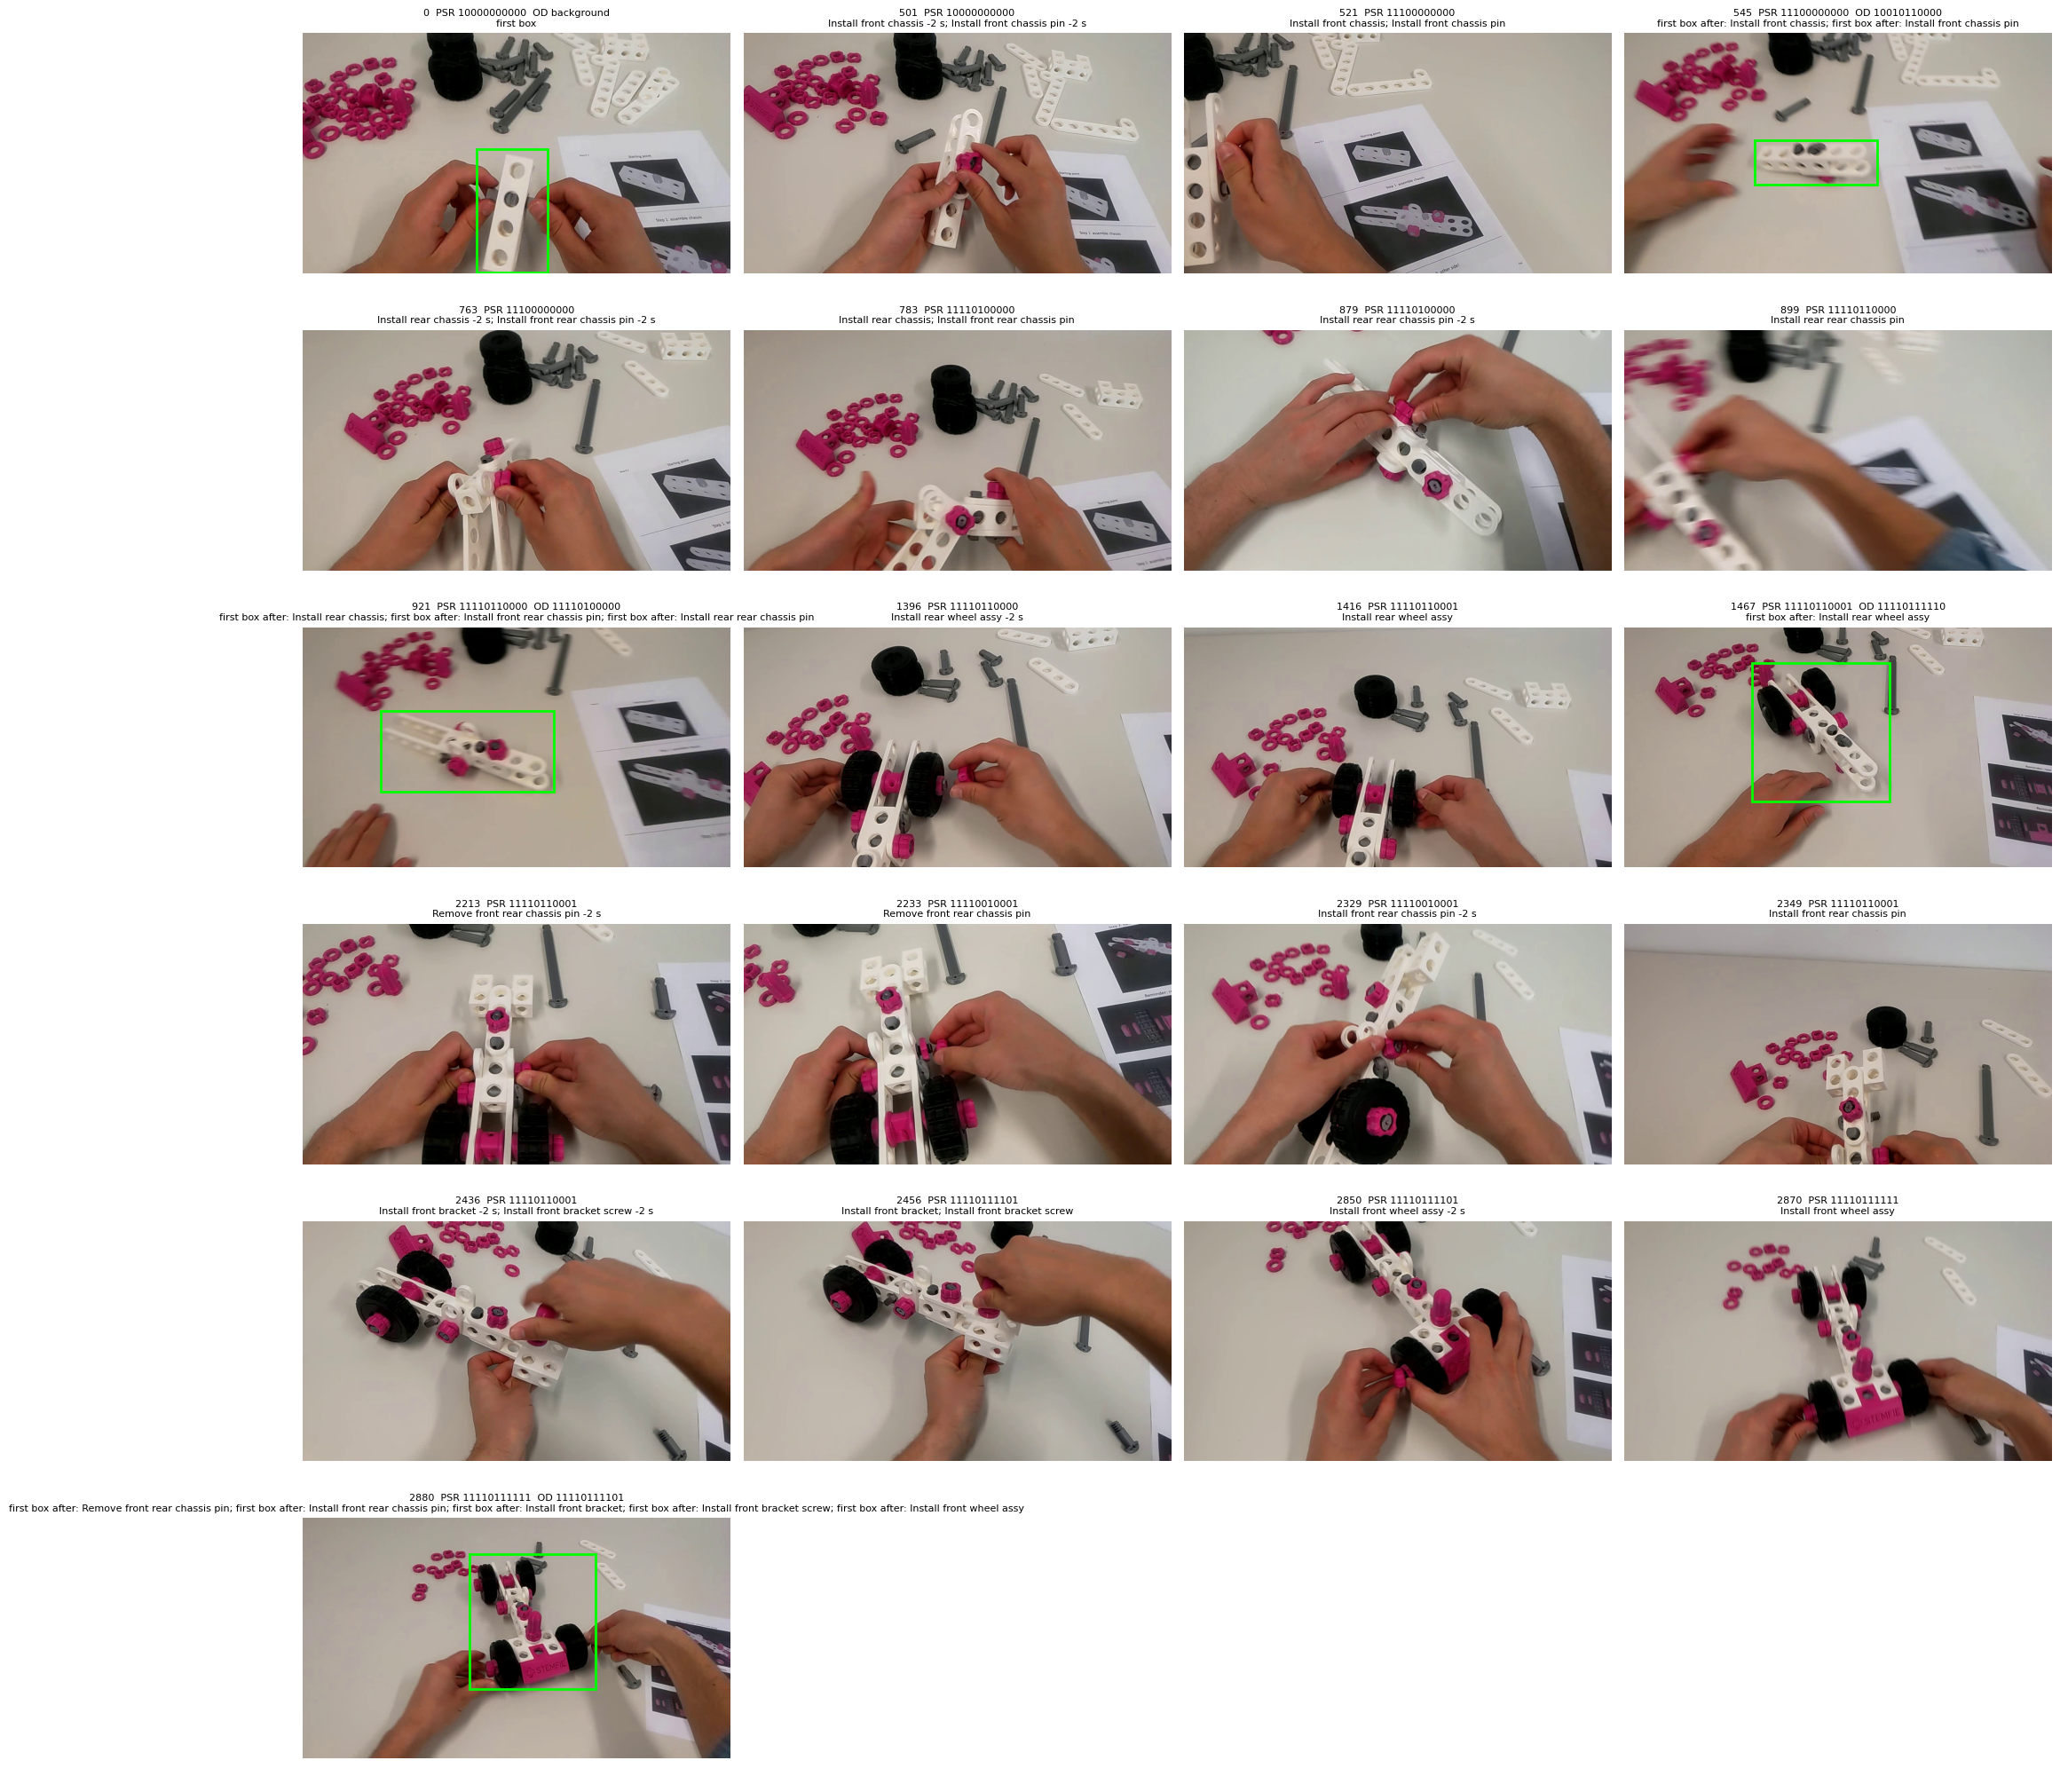

In [20]:
# 7.3 Contact sheet of 05_assy_0_1: steps, boxes and states
import matplotlib.pyplot as plt

boxes_by_frame = {frame_of[b["image_id"]]: b for b in od["annotations"]}
steps = read_rows(rec / "PSR_labels_with_errors.csv")
states = read_states(rec)

def state_at(frame):
    """PSR state vector in force at a frame, as a string (x = incorrect)."""
    current = states[0][1]
    for f, s in states:
        if int(f[:-4]) <= frame:
            current = s
    return "".join("x" if v == -1 else str(v) for v in current)

def read_frame(video, index):
    """One frame of a video, as an RGB array."""
    video.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, image = video.read()
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

shown = {}                                                         # frame -> reasons for showing it
def add(frame, reason):
    shown.setdefault(frame, []).append(reason)

add(min(boxes_by_frame), "first box")
for f, step_id, description in steps:
    f = int(f[:-4])
    add(max(f - 2 * FPS, 0), f"{description} -2 s")
    add(f, description)
    later = [b for b in boxes_by_frame if b >= f]
    if later:
        add(min(later), f"first box after: {description}")

frames = sorted(shown)
cols = 4
rows = -(-len(frames) // cols)
video = cv2.VideoCapture(str(VIDEOS_DIR / f"{rec.name}.mp4"))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.4 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, f in zip(axes.flat, frames):
    ax.imshow(read_frame(video, f))
    title = f"{f}  PSR {state_at(f)}"
    if f in boxes_by_frame:
        x, y, w, h = boxes_by_frame[f]["bbox"]
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color="lime", lw=2))
        title += f"  OD {category_name[boxes_by_frame[f]['category_id']]}"
    ax.set_title(title + "\n" + "; ".join(shown[f]), fontsize=8)
video.release()
plt.tight_layout()
plt.show()

Observation 7.3: The boxes always enclose the whole object being assembled, not a single component. At the frames of the steps the hands are on the object, and one frame is blurred; at the frames with a box the object lies on the desk and the hands are away or almost. The printed instructions, with rendered images of the car, are in view in most frames.

In [21]:
# 7.4 Box labels against PSR states, read as written and shifted by one
def psr_label_at(rec_states, frame):
    """PSR state in force at a frame, written as a category name: the 11 digits, or error_state if a component is incorrect."""
    current = rec_states[0][1]
    for f, s in rec_states:
        if int(f[:-4]) <= frame:
            current = s
    return "error_state" if -1 in current else "".join(str(v) for v in current)

category_lists = set()
total, agree_as_written, agree_shifted = 0, 0, 0
disagree_shifted = []
for rec in recordings:
    od_rec = json.loads((rec / "OD_labels.json").read_text())
    names = {c["id"]: c["name"] for c in od_rec["categories"]}
    category_lists.add(tuple(sorted(names.items())))
    rec_states = read_states(rec)
    frames = {img["id"]: int(img["file_name"][:-4]) for img in od_rec["images"]}
    for box in od_rec["annotations"]:
        frame = frames[box["image_id"]]
        truth = psr_label_at(rec_states, frame)
        total += 1
        agree_as_written += names[box["category_id"]] == truth
        shifted = names.get(box["category_id"] + 1)
        agree_shifted += shifted == truth
        if shifted != truth:
            disagree_shifted.append((rec.name, frame, shifted, truth))

print("Distinct category lists across the 84 files:", len(category_lists))
print(total, "boxes")
print(f"Agree with PSR, name as written: {agree_as_written} ({100 * agree_as_written / total:.1f}%)")
print(f"Agree with PSR, name of id + 1:  {agree_shifted} ({100 * agree_shifted / total:.1f}%)")
print("Disagreements with id + 1:", len(disagree_shifted))
for d in disagree_shifted[:15]:
    print("  ", d)

Distinct category lists across the 84 files: 1
26925 boxes
Agree with PSR, name as written: 6 (0.0%)
Agree with PSR, name of id + 1:  25875 (96.1%)
Disagreements with id + 1: 1050
   ('08_main_0_1', 13, '11110011111', '11110111111')
   ('08_main_0_1', 14, '11110011111', '11110111111')
   ('08_main_0_1', 15, '11110011111', '11110111111')
   ('08_main_0_1', 16, '11110011111', '11110111111')
   ('08_main_0_1', 17, '11110011111', '11110111111')
   ('08_main_0_1', 18, '11110011111', '11110111111')
   ('10_assy_3_2', 2577, 'error_state', '10000000010')
   ('10_assy_3_2', 2578, 'error_state', '10000000010')
   ('10_assy_3_2', 2579, 'error_state', '10000000010')
   ('10_assy_3_2', 2580, 'error_state', '10000000010')
   ('10_assy_3_2', 2581, 'error_state', '10000000010')
   ('10_assy_3_2', 2582, 'error_state', '10000000010')
   ('10_assy_3_2', 2583, 'error_state', '10000000010')
   ('10_assy_3_2', 2584, 'error_state', '10000000010')
   ('10_assy_3_2', 2585, 'error_state', '10000000010')


In [22]:
# 7.5 Disagreements between boxes (id + 1) and PSR states, by kind
from collections import Counter

LAG = 2 * FPS                                                      # a box state that the PSR reach within 2 s counts as a time offset
states_by_rec = {rec.name: read_states(rec) for rec in recordings}

def kind_of(rec_name, frame, box_label, psr_label):
    rec_states = states_by_rec[rec_name]
    nearby = {psr_label_at(rec_states, f) for f in range(max(frame - LAG, 0), frame + LAG + 1)}
    if box_label in nearby:
        return "time offset (within 2 s)"
    if box_label == "error_state":
        return "box error, PSR no error"
    if psr_label == "error_state":
        return "PSR error, box no error"
    return "different states, no error"

kinds = Counter(kind_of(*d) for d in disagree_shifted)
for kind, n in kinds.most_common():
    print(f"{kind}: {n}")
print()
print("Disagreements per recording:", Counter(d[0] for d in disagree_shifted).most_common())
print("Boxes with category_id 0 (background):", sum(
    box["category_id"] == 0 for rec in recordings
    for box in json.loads((rec / "OD_labels.json").read_text())["annotations"]))

box error, PSR no error: 1024
time offset (within 2 s): 26

Disagreements per recording: [('07_assy_2_3', 500), ('04_assy_2_1', 179), ('22_assy_2_3', 151), ('25_assy_2_1', 52), ('14_main_2_2', 29), ('19_main_0_1', 28), ('16_main_0_1', 21), ('10_assy_3_2', 20), ('05_assy_2_2', 19), ('21_assy_0_1', 16), ('01_assy_1_1', 11), ('24_main_0_1', 10), ('01_assy_0_1', 7), ('08_main_0_1', 6), ('27_main_0_1', 1)]
Boxes with category_id 0 (background): 0


In [23]:
# 7.6 Box errors without a PSR error: is the PSR state one of the 22 defined states?
defined_states = {c["name"] for c in od["categories"] if c["name"] not in ("background", "error_state")}
box_errors = [d for d in disagree_shifted if d[2] == "error_state"]
outside = [d for d in box_errors if d[3] not in defined_states]
print(len(defined_states), "defined states")
print(f"Box errors without a PSR error: {len(box_errors)}, of which PSR state not among the defined states: {len(outside)}")
print("PSR states inside the defined ones, by recording:", Counter(d[0] for d in box_errors if d[3] in defined_states).most_common())

22 defined states
Box errors without a PSR error: 1034, of which PSR state not among the defined states: 999
PSR states inside the defined ones, by recording: [('21_assy_0_1', 16), ('24_main_0_1', 10), ('01_assy_1_1', 9)]


Observation 7.4-7.6: The category of each box is the index of the list of categories in the dataset code, which starts at 0 (background), while the list of categories in the json files starts at 1. Read as written, the names of the boxes agree with the PSR states in 0.0% of the 26,925 boxes; read with the name of the next id, in 96.1%. The list of categories is the same in all 84 files, the 26,925 boxes are the 26.9K of the paper, and the category background is never used. From here on the boxes are always read with the shift.

Of the 1,050 remaining disagreements, 26 are offsets of less than 2 s between a box and the change of the PSR state. The other 1,024, and 10 of the offsets, are boxes labelled error_state where the PSR state has no incorrect component. In 999 of these 1,034 the PSR state is not one of the 22 defined states: the two annotations define an error differently. The PSR mark -1 only for a component installed incorrectly, while the boxes mark error_state whenever the object is not in a defined state, also for a missing step or a component in the place of another.

In the remaining 35 the PSR state is a defined one, yet the box is error_state, in 21_assy_0_1, 24_main_0_1 and 01_assy_1_1. There the box records an error that does not change the state of any component, for example a part with the wrong orientation (hypothesis, to be checked on the frames). Since all errors share one category, the 27 error states of the paper cannot be counted from the boxes; the extension of the dataset adds the error types.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 7:

IndustReal code repository, PSR/psr_utils.py at commit ad86a35: the list categories, from background (index 0) through the 22 states to error_state (index 23).

Schoonbeek et al. 2024, IndustReal (WACV), Section 4.3: participants remove their hands from the assembly after each step; Section 4.4.2: boxes for the 22 defined states and 27 error states, intermediate states not labelled, 26.9K annotated frames.

Schoonbeek et al. 2025, STORM-PSR (CVIU), Section 5.1: a box is drawn only if a human annotator can recognize the assembly state from a single image, the same procedure as for IndustReal; Section 4.4: boxes exist only when the whole object is largely unobstructed and within the frame; Section 2.1: IndustReal participants were asked to occasionally give an unobstructed view of the object; Section 6: a projected virtual box outlined the field of view of the camera during recording.

Extension to IndustReal Dataset: Assembly State Recognition with Error States (4TU.ResearchData, 2024): the original dataset labels all assembly errors with one generic error class; the extension adds the error types.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 8 - Statistics for the choice of frames

The frames to annotate are chosen with rules written before any result is looked at (Section 9), as for Mr Potato Head: parts loose on the desk and parts mounted, at different stages and distances. This section collects what the rules need. Only boxes whose state, read with the shift of Section 7, agrees with the PSR state of the same frame are used, so that the state of every chosen frame is certain.

In [24]:
# 8.1 Usable boxes (state agreeing with the PSR), by split and by state
import pandas as pd

rows = []
for rec in recordings:
    od_rec = json.loads((rec / "OD_labels.json").read_text())
    names = {c["id"]: c["name"] for c in od_rec["categories"]}
    frames = {img["id"]: int(img["file_name"][:-4]) for img in od_rec["images"]}
    for box in od_rec["annotations"]:
        frame = frames[box["image_id"]]
        state = names.get(box["category_id"] + 1)                  # read with the shift of Section 7
        x, y, w, h = box["bbox"]
        rows.append({"split": rec.parent.name, "recording": rec.name, "task": rec.name.split("_")[1],
                     "frame": frame, "state": state,
                     "agrees": state == psr_label_at(states_by_rec[rec.name], frame),
                     "area": w * h / (1280 * 720),                 # box area as a fraction of the frame
                     "bbox": (x, y, w, h)})                 

boxes = pd.DataFrame(rows)
usable = boxes[boxes.agrees]
print(len(boxes), "boxes,", len(usable), "agree with the PSR")
print(usable.groupby("split").agg(boxes=("frame", "size"), recordings=("recording", "nunique"), states=("state", "nunique")))
print()
train = usable[usable.split == "train"]
print(train.groupby("state").agg(boxes=("frame", "size"), recordings=("recording", "nunique")).sort_values("boxes"))
print()
print("Box area in train, as a fraction of the frame:", train.area.describe(percentiles=[0.1, 0.5, 0.9]).round(3).to_dict())

26925 boxes, 25875 agree with the PSR
       boxes  recordings  states
split                           
test    9647          32      18
train  13184          36      21
val     3044          16      18

             boxes  recordings
state                         
11110101110     26           2
11110011110     34           2
11110100000     65           4
10010010000     80           3
11110011111    126           5
11110111100    142           3
11110111101    226           5
11110010000    324           4
11101101110    340           8
10010100000    349           5
11110111110    425          12
10010110000    516           7
11101111111    561          13
11100000000    590          11
11101111110    709          11
11100001110   1066          14
error_state   1072          11
11110111111   1133          27
10000000000   1639          20
11110110000   1848          16
11110110001   1913          11

Box area in train, as a fraction of the frame: {'count': 13184.0, 'mean': 0.197, '

Observation 8.1: 25,875 of the 26,925 boxes agree with the PSR state; 13,184 of them are in train, spread over all 36 recordings. The train boxes cover 20 of the 22 defined states, plus error_state: 11110101111 and 11101011110 never occur in train. Some states are rare, such as 11110101110 (26 boxes in 2 recordings) and 11110011110 (34 boxes in 2 recordings), while the initial state 10000000000 has 1,639 boxes in 20 recordings and the complete car 11110111111 1,133 boxes in 27 recordings.

The states show the two orders of assembly, starting with the front chassis (states beginning with 111) or with the rear chassis (beginning with 1001), and the states of maintenance, with the rear chassis removed or replaced (a 0 in fourth place). The box covers a median of 18% of the frame, between 5% (10th percentile) and 36% (90th percentile): the object is seen at clearly different distances.

In [25]:
# 8.2 Start of each train recording: first action, first step, and usable boxes before the first step
start_rows = []
for rec in recordings:
    if rec.parent.name != "train":
        continue
    first_action = min(int(r[3][:-4]) for r in read_rows(rec / "AR_labels.csv"))
    first_step = min(int(r[0][:-4]) for r in read_rows(rec / "PSR_labels_with_errors.csv"))
    before = usable[(usable.recording == rec.name) & (usable.frame < first_step)]
    start_rows.append({"recording": rec.name, "first action": first_action, "first step": first_step,
                       "boxes before": len(before), "states before": " ".join(sorted(before.state.unique()))})
start = pd.DataFrame(start_rows)
print(start.to_string(index=False))
print()
for task in ("assy", "main"):
    s = start[start.recording.str.contains(task)]
    print(f"{task}: {len(s)} recordings, {(s['boxes before'] > 0).sum()} with usable boxes before the first step, "
          f"first action at {s['first action'].median() / FPS:.1f} s (median)")

  recording  first action  first step  boxes before states before
01_assy_0_1            28         198            42   10000000000
01_assy_1_1            27         272            69   10000000000
01_main_0_1            37          78            61   11110111111
02_assy_0_1            38         448           244   10000000000
02_assy_1_2            45         747           107   10000000000
02_main_0_1            31          98            71   11110111111
04_assy_0_1            83        1170           120   10000000000
04_assy_2_1            35         565            89   10000000000
04_main_0_1            42          85            61   11110111111
06_assy_0_1            51         322            49   10000000000
06_assy_1_4            35         333            11   10000000000
06_main_0_1            32         165            63   11110111111
07_assy_0_1           125         362           134   10000000000
07_assy_2_3            35         565            62   10000000000
07_main_0_

Observation 8.2: All 20 assembly recordings of train have usable boxes before their first step, always in state 10000000000: the base, with every other part loose on the desk. They range from 4 boxes (22_assy_0_1) to 261 (22_assy_2_3). All 16 maintenance recordings start with usable boxes of the complete car (11110111111), except 27_main_3_1, which starts in error_state, a car with a component already incorrect. Both scenes needed for the support set, everything loose and everything mounted, are therefore present in almost every recording.

The first action starts after about 3.5 s in assembly and 3.2 s in maintenance (median), at frame 0 in 22_assy_0_1. The first action can be check_instruction, so it does not tell when the hands first touch a part.

Within a short group of boxes after a step the scene is the same, and frames differ mainly in motion blur from the movement of the head. The sharpest frame of each group is found with the variance of the Laplacian inside the box, a measure of focus that is low when edges are blurred (Pertuz et al. 2013). Ego4D uses the same measure to discard blurred egocentric frames, with a fixed threshold. Here frames are only compared within the same scene, so no threshold is needed: the absolute value depends on the content of the image. The measure was made for defocus; whether it ranks motion blur in the same way is checked by eye in 8.4.

In [26]:
# 8.3 Sharpness of the usable train boxes: variance of the Laplacian inside the box, on the video frames
def sharpness(image, bbox):
    x, y, w, h = (int(round(v)) for v in bbox)
    x, y = max(x, 0), max(y, 0)
    crop = cv2.cvtColor(image[y:y + h, x:x + w], cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(crop, cv2.CV_64F).var()

train_boxes = usable[usable.split == "train"].copy()
if SHARPNESS_PATH.exists():
    saved = pd.read_csv(SHARPNESS_PATH)
    values = {(r, f): s for r, f, s in zip(saved.recording, saved.frame, saved.sharpness)}
else:
    values = {}
    for rec, group in train_boxes.groupby("recording"):
        offset = VIDEO_OFFSET.get(rec, 0)
        wanted = {f - offset: (f, b) for f, b in zip(group.frame, group.bbox)}
        video = cv2.VideoCapture(str(VIDEOS_DIR / f"{rec}.mp4"))
        i, last = 0, max(wanted)
        while i <= last and video.grab():
            if i in wanted:
                _, image = video.retrieve()
                f, b = wanted[i]
                values[(rec, f)] = sharpness(image, b)
            i += 1
        video.release()
    pd.DataFrame([(r, f, s) for (r, f), s in values.items()],
                 columns=["recording", "frame", "sharpness"]).to_csv(SHARPNESS_PATH, index=False)

train_boxes["sharpness"] = [values[(r, f)] for r, f in zip(train_boxes.recording, train_boxes.frame)]
print(len(train_boxes), "boxes in", train_boxes.recording.nunique(), "recordings")
print(train_boxes.sharpness.describe().round(1).to_string())

13184 boxes in 36 recordings
count    13184.0
mean       112.2
std         70.3
min          4.1
25%         59.1
50%        101.5
75%        148.2
max        633.0


Observation 8.3: The variance of the Laplacian inside the 13,184 usable train boxes, in 36 recordings, ranges from 4.1 to 633.0, with median 101.5 and quartiles 59.1 and 148.2. The value depends also on what the box contains (how many edges are visible, the size and distance of the assembly), so it is compared only between frames of the same recording and of the same group of consecutive boxes, never with a fixed threshold; the threshold of 100 used in Ego4D was set on whole frames of another camera and does not transfer. Whether low values are blurred frames is checked by eye in 8.4.

Median sharpness per recording:
count     36.0
mean     104.9
std       36.3
min       54.8
25%       78.8
50%       95.0
75%      129.4
max      198.9


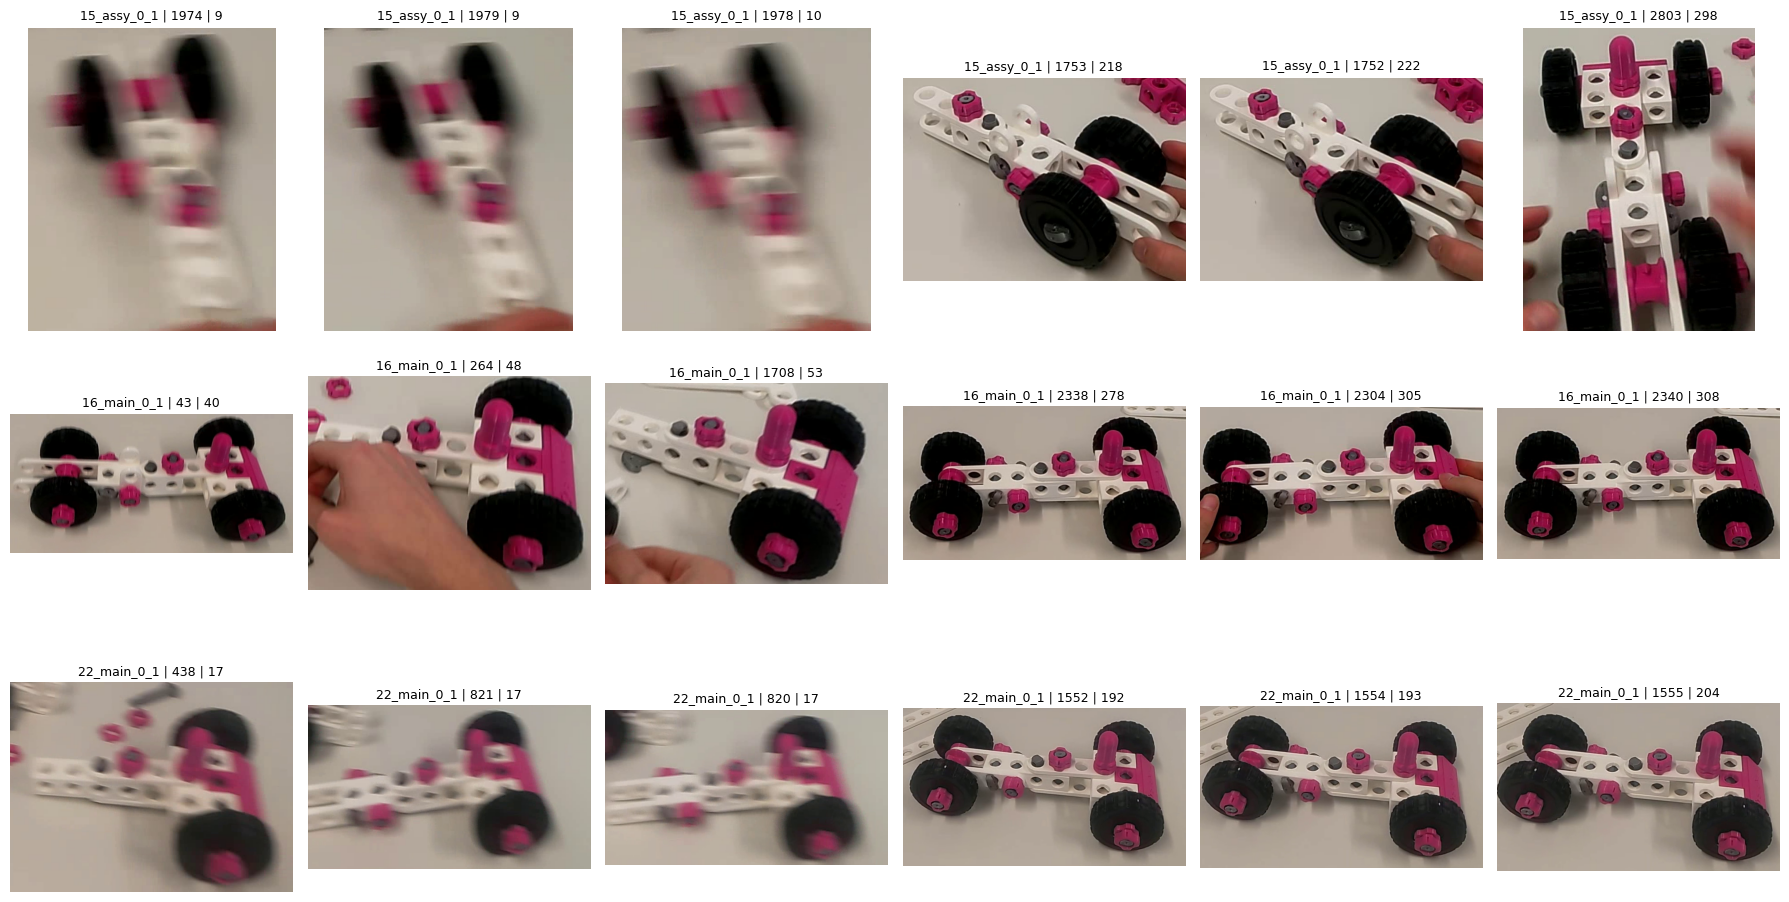

In [27]:
# 8.4 Visual check of the sharpness: the 3 least sharp and the 3 sharpest boxes of three train recordings
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
check_recs = sorted(rng.choice(train_boxes.recording.unique(), 3, replace=False))
print("Median sharpness per recording:")
print(train_boxes.groupby("recording").sharpness.median().describe().round(1).to_string())

fig, axes = plt.subplots(len(check_recs), 6, figsize=(18, 3.2 * len(check_recs)))
for row, rec in zip(axes, check_recs):
    boxes = train_boxes[train_boxes.recording == rec].sort_values("sharpness")
    chosen = pd.concat([boxes.head(3), boxes.tail(3)])
    offset = VIDEO_OFFSET.get(rec, 0)
    wanted = {f - offset for f in chosen.frame}
    frames, video, i = {}, cv2.VideoCapture(str(VIDEOS_DIR / f"{rec}.mp4")), 0
    while i <= max(wanted) and video.grab():
        if i in wanted:
            frames[i + offset] = video.retrieve()[1]
        i += 1
    video.release()
    for ax, (_, box) in zip(row, chosen.iterrows()):
        x, y, w, h = (int(round(v)) for v in box.bbox)
        crop = frames[box.frame][max(y, 0):y + h, max(x, 0):x + w]
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{rec} | {box.frame} | {box.sharpness:.0f}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

Observation 8.4: In 15_assy_0_1 and 22_main_0_1 the three least sharp boxes (9 to 17) are motion blurred and the three sharpest (192 to 308) are still and sharp. In 16_main_0_1 the three least sharp boxes (40 to 53) are not blurred: in one the assembly is far and small, in two a hand covers a large part of the box from close by, so their low value comes from the content, not from motion. Blurred frames come in short runs (1974, 1978 and 1979 in 15_assy_0_1), as a head movement does. The median sharpness per recording ranges from 54.8 to 198.9. So neither a fixed threshold nor discarding the least sharp frames of each recording separates blurred frames from still ones; taking the sharpest frame within a group of consecutive boxes does avoid a run of blurred frames, and the chosen frame is looked at before it is annotated.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8:

Pertuz et al. 2013, Analysis of focus measure operators for shape-from-focus (Pattern Recognition), Appendix A.20, Eq. (A.27): the variance of the Laplacian (LAP4); Section 5, p. 1425: Laplacian-based operators perform best under normal imaging conditions, and the texture content of the image influences focus measures.

Pech-Pacheco et al. 2000, Diatom autofocusing in brightfield microscopy: a comparative study (ICPR), Section 1, p. 314: the variance of the image Laplacian proposed as a focus measure; reference [65] of Pertuz et al. for this operator.

Grauman et al. 2022, Ego4D (CVPR, arXiv:2110.07058), appendix on VQ3D, camera pose estimation, Step 1, p. 36: non-blurry egocentric frames selected with a variance of the Laplacian above a threshold of 100.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 9 - Rules for the choice of frames

The frames to annotate with polygons are chosen here, with rules fixed before any frame is annotated and before any prediction is made, as for Mr Potato Head. The candidates for the support set come from train, the validation frames from validation and the test frames from test, which stays blind until the single measure at the end.

The scenes to cover are those of Mr Potato Head: everything loose on the desk (state 10000000000, before the first step), the car at different stages, and the complete car (11110111111, at the end of an assembly and at the start of a maintenance), seen from different distances (area of the box, Section 8).

One frame is taken from each group of boxes that show the same scene. This way the same scene is not annotated twice, and the evaluation frames are not near copies of each other. In the support set the frame of a group is the sharpest one (Section 8). In validation and test it is the box closest to the centre of the group, chosen without looking at sharpness, and it is never replaced because of how it looks, as in the test of Mr Potato Head.

Motion blur is part of egocentric video (Grauman et al. 2022), so the evaluation keeps it in the proportion in which it occurs. Each evaluation frame gets a note, blurred or not, given by eye before it is annotated. A frame is discarded only if the contours of the parts cannot be drawn, and discarded frames are counted.

Cell 9.1 counts the groups with two definitions before one is chosen.

In [28]:
# 9.1 Groups of usable boxes: runs of consecutive frames against pairs of recording and state
SCENES = {"10000000000": "all loose", "11110111111": "complete car",
          "11101111111": "complete, maintained", "error_state": "error state"}   # every other state is an intermediate stage

print("Frames with more than one usable box:", usable.duplicated(["recording", "frame"]).sum())

run_rows = []
for (split, rec, task, state), g in usable.groupby(["split", "recording", "task", "state"]):
    frames = np.unique(g.frame.to_numpy())
    breaks = np.flatnonzero(np.diff(frames) != 1)            # a run ends where the next box is not on the next frame
    starts = np.r_[frames[0], frames[breaks + 1]]
    ends = np.r_[frames[breaks], frames[-1]]
    for k, (s, e) in enumerate(zip(starts, ends)):
        run_rows.append({"split": split, "recording": rec, "task": task, "state": state,
                         "scene": SCENES.get(state, "intermediate"), "run": k,
                         "start": s, "end": e, "seconds": (e - s + 1) / FPS})
runs = pd.DataFrame(run_rows)
pairs = runs.groupby(["split", "recording", "task", "state", "scene"]).size().rename("runs").reset_index()

summary = pd.DataFrame({
    "runs": runs.groupby("split").size(),
    "recording-state pairs": pairs.groupby("split").size(),
    "pairs with more than one run": pairs[pairs.runs > 1].groupby("split").size(),
    "recordings": runs.groupby("split").recording.nunique(),
    "states": runs.groupby("split").state.nunique(),
}).fillna(0).astype(int)
print(summary.to_string())
print()
print("Runs by task and scene:")
print(pd.crosstab(runs.split, [runs.task, runs.scene]).to_string())
print()
print("Recording-state pairs by task and scene:")
print(pd.crosstab(pairs.split, [pairs.task, pairs.scene]).to_string())
print()
print("Run length in seconds:", runs.seconds.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_dict())

gaps = []                                                    # frames without a box between two runs of the same recording and state
for _, g in runs.sort_values("start").groupby(["recording", "state"]):
    gaps += list(g.start.to_numpy()[1:] - g.end.to_numpy()[:-1] - 1)
gaps = pd.Series(gaps, dtype=int)
print()
print(len(gaps), "gaps between runs of the same recording and state, in frames:")
print(gaps.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_dict())
print("Smallest gaps (frames: how many):", gaps.value_counts().sort_index().head(10).to_dict())

Frames with more than one usable box: 0
       runs  recording-state pairs  pairs with more than one run  recordings  states
split                                                                               
test    272                    181                            56          32      18
train   314                    194                            58          36      21
val     117                     88                            18          16      18

Runs by task and scene:
task       assy                                                                    main                                              
scene all loose complete car complete, maintained error state intermediate complete car complete, maintained error state intermediate
split                                                                                                                                
test         24            9                    0          23          130           14                   12

Observation 9.1: Every frame has at most one usable box. The usable boxes form 703 runs of consecutive frames (314 in train, 117 in validation, 272 in test) but only 463 pairs of recording and state (194, 88 and 181). In 132 pairs the same state appears in more than one run. A run lasts 2.6 s in the median, between 0.7 s (10th percentile) and 7.6 s (90th percentile), and at most 58.5 s.

The 240 gaps between runs of the same recording and state range from 1 frame to 3796 frames (more than 6 minutes), with median 30.5 frames (3 s), quartiles 14 and 100.5 frames and 90th percentile 322 frames. Only 36 gaps are of 10 frames or less. So the two definitions of a group differ, and the gaps show no natural break between an interruption of the same scene and a return to the same state later.

The pairs agree with Section 8. In train, everything loose has 20 pairs, one per assembly recording (8.2); the complete car 11110111111 has 27 (12 assembly, 15 maintenance); error_state 11; and the end of a maintenance, 11101111111, 13, of which 2 are assembly recordings. These are the numbers of recordings of Section 8.1, so each recording passes through each state at most in one pair, and a count of pairs is a count of recordings. Validation and test have the same kinds of scenes, except that no assembly recording reaches 11101111111 and no validation maintenance has boxes in error_state.

In [29]:
# 9.2 Actions in progress when a step is completed, and steps completed during the actions not tied to one part
step_info = {s["id"]: s for s in procedure}
actions_by_rec = {}
for a in actions:                                                      # (recording, task, id, name, first frame, last frame), from 6.1
    actions_by_rec.setdefault(a[0], []).append(a)

completions = {}                                                       # recording -> [(frame, component)] of every installation
totals, in_progress, nothing = Counter(), {c: Counter() for c in COMPONENTS}, Counter()
for rec in recordings:
    own = actions_by_rec.get(rec.name, [])
    for f, step_id, _ in read_rows(rec / "PSR_labels_with_errors.csv"):
        step = step_info[int(step_id)]
        if not step["install"]:
            continue                                                   # removals are not mountings
        f, component = int(f[:-4]), COMPONENTS[step["state_idx"]]      # installations, correct or incorrect
        completions.setdefault(rec.name, []).append((f, component))
        totals[component] += 1
        names = {a[3] for a in own if a[4] <= f <= a[5]}
        in_progress[component].update(names)
        nothing[component] += not names

for c in COMPONENTS:
    print(f"{c}: {totals[c]} installations, {nothing[c]} with no action in progress")
    print("   ", in_progress[c].most_common(6))

print()
for name in ("fit_partial_model", "plug_partial_model", "fit_objects", "plug_objects", "take_partial_model", "take_objects"):
    inst = [a for a in actions if a[3] == name]
    done = Counter(c for a in inst for f, c in completions.get(a[0], []) if a[4] <= f <= a[5])
    with_step = sum(any(a[4] <= f <= a[5] for f, _ in completions.get(a[0], [])) for a in inst)
    print(f"{name}: {len(inst)} instances, {with_step} with an installation completed during them; components {dict(done)}")
for a in actions:
    if a[3] in ("fit_partial_model", "plug_partial_model"):
        print("   ", a[0], a[3], "frames", a[4], "-", a[5])

base: 0 installations, 0 with no action in progress
    []
front chassis: 51 installations, 5 with no action in progress
    [('tighten_nut', 44), ('check_instruction', 6), ('take_long_brace', 1)]
front chassis pin: 51 installations, 5 with no action in progress
    [('tighten_nut', 44), ('check_instruction', 6), ('take_long_brace', 1)]
rear chassis: 51 installations, 3 with no action in progress
    [('tighten_nut', 43), ('align_objects', 9), ('check_instruction', 2), ('put_partial_model', 2)]
short rear chassis: 39 installations, 1 with no action in progress
    [('tighten_nut', 35), ('align_objects', 4), ('check_instruction', 1)]
front rear chassis pin: 89 installations, 4 with no action in progress
    [('tighten_nut', 77), ('align_objects', 11), ('put_partial_model', 3), ('check_instruction', 2)]
rear rear chassis pin: 83 installations, 3 with no action in progress
    [('tighten_nut', 79), ('check_instruction', 7), ('align_objects', 2)]
front bracket: 50 installations, 4 with no 

Observation 9.2: The base is never installed, since it is on the desk from the start. For every other component the installation is completed, in most cases, while a nut is being tightened: tighten_nut for the chassis, the pins and the wheels (for example 79 of 83 installations of the rear rear chassis pin), tighten_acorn_nut for the front bracket and its screw (41 of 50 and 42 of 51), and one of the two for the front wheel (32 and 11 of 49). Between 1 and 5 installations per component are completed with no action in progress. So the PSR mark a component as installed when it is fastened, not when it is put in place.

The front chassis and its pin have the same counts, as in 05_assy_0_1, where both are completed at frame 521 (4.3); the front bracket and its screw almost the same. No installation is completed during fit_ or plug_ of partial_model (5 instances) or objects (183 instances), nor during take_objects, and 2 of the 302 take_partial_model. This does not tell what these actions are: if they insert a part, its installation is completed later, when it is fastened.

In [30]:
# 9.3 Insertions before each installation: fit_ and plug_ actions started since the previous installation
MOUNT_VERBS = ("fit_", "plug_")
inserted, without = {c: Counter() for c in COMPONENTS}, Counter()
for rec_name, done in completions.items():                           # completions and totals from 9.2
    own = [a for a in actions_by_rec.get(rec_name, []) if a[3].startswith(MOUNT_VERBS)]
    frames = sorted({f for f, _ in done})
    for f, component in done:
        earlier = [g for g in frames if g < f]
        since = earlier[-1] if earlier else -1                         # previous installation completed in this recording
        names = {a[3] for a in own if since < a[4] <= f}               # fit_ and plug_ started after it, up to this completion
        inserted[component].update(names)
        without[component] += not names

for c in COMPONENTS[1:]:                                               # the base is never installed (9.2)
    print(f"{c}: {totals[c]} installations, {without[c]} with no fit_ or plug_ since the previous one")
    print("   ", inserted[c].most_common(8))

front chassis: 51 installations, 0 with no fit_ or plug_ since the previous one
    [('fit_tooth_washer', 48), ('fit_nut', 48), ('plug_short_pin', 47), ('fit_short_brace', 45), ('plug_objects', 4), ('plug_screw_pin', 4), ('fit_objects', 3), ('plug_small_screw_pin', 2)]
front chassis pin: 51 installations, 0 with no fit_ or plug_ since the previous one
    [('fit_tooth_washer', 48), ('fit_nut', 48), ('plug_short_pin', 47), ('fit_short_brace', 45), ('plug_objects', 4), ('plug_screw_pin', 4), ('fit_objects', 3), ('plug_small_screw_pin', 2)]
rear chassis: 51 installations, 0 with no fit_ or plug_ since the previous one
    [('fit_nut', 50), ('fit_tooth_washer', 47), ('plug_short_pin', 45), ('fit_long_brace', 18), ('plug_objects', 5), ('plug_screw_pin', 3), ('plug_partial_model', 2), ('fit_short_brace', 2)]
short rear chassis: 39 installations, 0 with no fit_ or plug_ since the previous one
    [('fit_nut', 37), ('fit_tooth_washer', 37), ('plug_short_pin', 36), ('fit_short_brace', 14), ('pl

Observation 9.3: Between two installations there is almost always at least one fit_ or plug_ action: only one installation of the front bracket, with its screw, and one of the front wheel have none. These actions are the parts of the component and their fasteners. Before the front chassis is installed there are, in 45 to 48 of 51 installations, fit_short_brace, plug_short_pin, fit_tooth_washer and fit_nut. Before the front bracket there are plug_screw_pin, fit_round_washer, fit_wing_beam and fit_acorn_nut (35 to 45 of 50). Before the wheels there are fit_wheel, the washers and the nut in 44 of 49 front and 81 to 83 of 84 rear installations.

plug_objects is part of the mounting of the wheels: it appears before 35 of the 49 installations of the front wheel and 69 of the 84 of the rear wheel, and more rarely before the chassis. So actions on several parts at once are real insertions, like the nose and the moustache entering the slot together in Mr Potato Head, and cannot be excluded by their name. The counts describe what is done between two installations, not to which component each action belongs: work on another component can fall in the same window, for example fit_wheel before 9 installations of the front bracket.

The moments of the pick and mount frames follow the event log of Mr Potato Head, where the mount frame comes from the insert, the first frame a piece touches the part it is mounted on, and the moment it is pushed in is recorded but not used to choose frames.

A mount frame is taken from the start of a fit_ or plug_ action, also on objects or partial_model, since these are real insertions (9.3). tighten_ actions give no frame: they fasten a part already inserted, and the PSR mark that moment as the installation (9.2). A pick frame is taken from the start of a take_ action of the parts, also take_objects. take_instruction and take_partial_model give no frame: in Mr Potato Head a pick is always the pick of a piece to mount, and lifting the car brings no new part into the hand. The action only fixes the moment; what is visible in the frame is recorded by the annotation.

In [31]:
# 9.4 Draw of the validation and test frames: 11 table, 11 pick and 11 mount frames per split
EXCLUDED_PICKS = ("take_instruction", "take_partial_model")     # no new part in the hand (markdown above)
STRATA = {"all loose": "all loose", "intermediate": "intermediate", "complete car": "all mounted",
          "complete, maintained": "all mounted", "error state": "error state"}   # scenes of the table frames

def eval_candidates(split):
    """Candidate frames of one split for each moment: table, pick and mount."""
    rows = []
    for (rec, state), g in runs[runs.split == split].groupby(["recording", "state"]):
        longest = g.sort_values(["seconds", "start"], ascending=[False, True]).iloc[0]   # longest run, the first on ties
        rows.append({"moment": "table", "recording": rec, "frame": int((longest.start + longest.end) // 2),
                     "action": None})                          # box at the centre of the run
    split_recs = {r.name for r in recordings if r.parent.name == split}
    for a in actions:                                          # (recording, task, id, name, first frame, last frame)
        if a[0] not in split_recs:
            continue
        if a[3].startswith("take_") and a[3] not in EXCLUDED_PICKS:
            rows.append({"moment": "pick", "recording": a[0], "frame": a[4], "action": a[3]})
        elif a[3].startswith(MOUNT_VERBS):
            rows.append({"moment": "mount", "recording": a[0], "frame": a[4], "action": a[3]})
    cands = pd.DataFrame(rows)
    cands["participant"] = cands.recording.str.split("_").str[0]
    cands["state"] = [psr_label_at(states_by_rec[r], f) for r, f in zip(cands.recording, cands.frame)]
    cands["scene"] = cands.state.map(lambda s: SCENES.get(s, "intermediate"))
    cands["stratum"] = cands.scene.map(STRATA)
    return cands

def draw(cands, n, rng, by_scene=False):
    """n candidates from different recordings, spread over participants: a participant is used again only when
    every participant with candidates left has been used as often; with by_scene, first one candidate per scene."""
    chosen, counts = [], Counter()

    def choose(mask):
        used = set(cands.loc[chosen, "recording"])
        pool = cands[mask & ~cands.index.isin(chosen) & ~cands.recording.isin(used)]
        if pool.empty:
            return False
        uses = pool.participant.map(lambda p: counts[p])
        i = rng.choice(pool.index[uses == uses.min()])         # among the least used participants
        chosen.append(i)
        counts[cands.at[i, "participant"]] += 1
        return True

    if by_scene:
        for stratum in ("all loose", "intermediate", "all mounted", "error state"):   # skipped if a split has none
            if len(chosen) < n:
                choose(cands.stratum == stratum)
    while len(chosen) < n:
        if not choose(pd.Series(True, index=cands.index)):
            raise ValueError("not enough candidates")
    return cands.loc[chosen]

rng = np.random.default_rng(SELECTION_SEED)
selected = []
for split in ("val", "test"):
    cands = eval_candidates(split)
    print(split, "candidates:", cands.moment.value_counts().to_dict(), "| participants:", cands.participant.nunique())
    for moment in ("table", "pick", "mount"):
        selected.append(draw(cands[cands.moment == moment], FRAMES_PER_MOMENT, rng,
                             by_scene=(moment == "table")).assign(split=split))

eval_frames = pd.concat(selected, ignore_index=True)
eval_frames["task"] = eval_frames.recording.str.split("_").str[1]
eval_frames["jpg"] = [f"{f:06d}.jpg" for f in eval_frames.frame]
eval_frames["blurred"] = None                                  # yes or no, given by eye before annotating
eval_frames["discarded"] = None                                # yes only if the contours of the parts cannot be drawn
eval_frames = eval_frames[["split", "moment", "recording", "participant", "task", "frame", "jpg",
                           "state", "scene", "action", "blurred", "discarded"]]

print()
print("Same frame chosen twice:", eval_frames.duplicated(["recording", "frame"]).sum())
print(eval_frames.groupby(["split", "moment"]).agg(frames=("frame", "size"), recordings=("recording", "nunique"),
                                                   participants=("participant", "nunique")).to_string())
print()
print(pd.crosstab([eval_frames.split, eval_frames.moment], eval_frames.scene).to_string())
print()
print(pd.crosstab(eval_frames.split, eval_frames.task).to_string())

if EVAL_FRAMES_PATH.exists():
    saved = pd.read_csv(EVAL_FRAMES_PATH)
    same = saved[["split", "moment", "recording", "frame"]].equals(eval_frames[["split", "moment", "recording", "frame"]])
    print("\nSaved list present; same frames as this draw:", same)
else:
    eval_frames.to_csv(EVAL_FRAMES_PATH, index=False)
    print("\nList written to", EVAL_FRAMES_PATH)

val candidates: {'pick': 541, 'mount': 436, 'table': 88} | participants: 5
test candidates: {'pick': 1094, 'mount': 864, 'table': 181} | participants: 10

Same frame chosen twice: 0
              frames  recordings  participants
split moment                                  
test  mount       11          11            10
      pick        11          11            10
      table       11          11            10
val   mount       11          11             5
      pick        11          11             5
      table       11          11             5

scene         all loose  complete car  complete, maintained  error state  intermediate
split moment                                                                          
test  mount           3             0                     0            2             6
      pick            2             0                     0            0             9
      table           3             1                     1            2             4
val   

Observation 9.4: The candidates are 88 table frames in validation and 181 in test, one per pair of recording and state as in 9.1, 541 and 1094 pick frames, and 436 and 864 mount frames. The draw gives 11 frames per moment and split, each from a different recording, with all participants used in every moment: 5 in validation and 10 in test. No frame is chosen twice. Validation has 23 frames from assemblies and 10 from maintenances, test 22 and 11.

The table frames cover every scene in both splits: in validation 3 with everything loose, 4 intermediate, 2 with the complete car, 1 at the end of a maintenance and 1 in error_state; in test 3, 4, 1, 1 and 2. The pick and mount frames are mostly intermediate; some fall in state 10000000000 (2 pick frames and 3 mount frames in test, 2 mount frames in validation), because the first parts are inserted before the PSR mark the first component as installed, when it is fastened (9.2).

This is the second draw. The first one, at commit 1133321, spread the frames over recordings only, and its test table frames had no complete car. After seeing those counts by scene, and before looking at any image, the rule was changed: participants are used evenly, and the table frames take one frame per scene first. The list is written to configs/industreal_eval_frames.csv and is not drawn again: a later run only checks that the draw gives the same frames.

Whether 33 frames per split are enough is decided on the validation measure, not by eye. After the validation frames are annotated and measured, the 95% interval of the score is computed with the bootstrap over frames (Koehn 2004), as for Mr Potato Head. If it is too wide, a second block of frames is drawn with the same rules from the candidates left and annotated. How wide is too wide is fixed once the time to annotate one frame is known, and before the first measure.